# Face Verification & Identification — Residual CNN + Batch-Hard Triplet Loss

A face recognition pipeline built with TensorFlow/Keras on the **LFW** dataset (deep-funneled):

1. **Data & training** — 5,985 images of 423 identities (≥ 5 images each), grayscale 96×96, class-balanced batches (16 identities × 4 images), residual CNN producing 128-d L2-normalized embeddings, trained with a Batch-Hard Triplet Loss.
2. **Evaluation** — ROC curve, EER, TAR@FAR, precision/recall and confusion matrix on random image pairs from the held-out split.
3. **Inference** — `verify()` compares two images, `identify()` finds the closest identity in a gallery.

> **Dataset required:** download LFW (deep-funneled) and place it in `./lfw_dataset/lfw-deepfunneled/lfw-deepfunneled/` (not included in this repository).
>
> **Note on evaluation:** the test split contains new images of identities also seen in training, and the threshold is selected on the test pairs, so results are optimistic and not comparable to the official LFW benchmark.

## 1. Data, model and training

In [1]:


import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

import numpy as np
import pandas as pd
import random
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from PIL import Image

tf.random.set_seed(42)
np.random.seed(42)
random.seed(42)

# ═════════════════════════════════════════════
# 1. DONNÉES
# ═════════════════════════════════════════════
IMG_SIZE = 96
EMB_DIM  = 128
EPOCHS   = 100
P        = 16   # personnes par batch
K        = 4    # images par personne → BATCH_SIZE = 64

base_path = "./lfw_dataset/lfw-deepfunneled/lfw-deepfunneled"

data = []
for person in os.listdir(base_path):
    pdir = os.path.join(base_path, person)
    if os.path.isdir(pdir):
        for img in os.listdir(pdir):
            if img.endswith(".jpg"):
                data.append([person, os.path.join(pdir, img)])

df = pd.DataFrame(data, columns=["person", "path"])
counts = df["person"].value_counts()
df = df[df["person"].isin(counts[counts >= 5].index)].reset_index(drop=True)
print(f"✅ df — {len(df)} images, {df['person'].nunique()} personnes")

def load_image(path: str) -> np.ndarray:
    img = Image.open(path).convert("L")
    img = img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    return (np.array(img, dtype=np.float32) / 255.0)[..., np.newaxis]

le = LabelEncoder()
df["label"] = le.fit_transform(df["person"])
print(f"Classes : {df['label'].nunique()}  |  Images : {len(df)}")

print("Chargement images…")
X, Y = [], []
for _, row in df.iterrows():
    try:
        X.append(load_image(row["path"]))
        Y.append(row["label"])
    except Exception as e:
        print(f"  ⚠ skip {row['path']}: {e}")

X = np.array(X, dtype=np.float32)
Y = np.array(Y, dtype=np.int32)

idx_tr, idx_te = train_test_split(np.arange(len(X)), test_size=0.2,
                                   stratify=Y, random_state=42)
X_train, y_train = X[idx_tr], Y[idx_tr]
X_test,  y_test  = X[idx_te], Y[idx_te]

mu, sigma = X_train.mean(), X_train.std() + 1e-8
X_train = (X_train - mu) / sigma
X_test  = (X_test  - mu) / sigma
print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")


# ═════════════════════════════════════════════
# 2. GÉNÉRATEUR ÉQUILIBRÉ PAR CLASSE
# ═════════════════════════════════════════════
class ClassBalancedGenerator(tf.keras.utils.Sequence):
    def __init__(self, X, y, P=16, K=4, augment=True, **kwargs):
        super().__init__(**kwargs)
        self.X, self.y = X, y
        self.P, self.K = P, K
        self.augment   = augment
        self.class_idx = {cls: np.where(y == cls)[0] for cls in np.unique(y)}
        self.classes   = list(self.class_idx.keys())
        self.steps     = max(1, len(X) // (P * K))

    def __len__(self):
        return self.steps

    def _augment(self, img):
        if random.random() < 0.5:
            img = img[:, ::-1, :]
        img = img + np.random.normal(0, 0.02, img.shape).astype(np.float32)
        return np.clip(img, -3.0, 3.0)

    def __getitem__(self, _):
        chosen = random.sample(self.classes, min(self.P, len(self.classes)))
        bx, by = [], []
        for cls in chosen:
            idxs = self.class_idx[cls]
            sel  = np.random.choice(idxs, size=self.K, replace=len(idxs) < self.K)
            for i in sel:
                img = self.X[i].copy()
                if self.augment:
                    img = self._augment(img)
                bx.append(img)
                by.append(cls)
        return np.array(bx, dtype=np.float32), np.array(by, dtype=np.float32)


# ═════════════════════════════════════════════
# 3. MODÈLE D'EMBEDDING
# ═════════════════════════════════════════════
def residual_block(x, filters):
    shortcut = x
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    if shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, padding='same', use_bias=False)(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    x = layers.add([x, shortcut])
    return layers.Activation('relu')(x)

def build_embedding_network(input_shape=(96, 96, 1), emb_dim=128):
    inp = layers.Input(shape=input_shape)
    x = layers.Conv2D(32, 3, padding='same', use_bias=False)(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling2D(2)(x)
    x = residual_block(x, 32);  x = residual_block(x, 32)
    x = layers.MaxPooling2D(2)(x)
    x = residual_block(x, 64);  x = residual_block(x, 64)
    x = layers.MaxPooling2D(2)(x)
    x = residual_block(x, 128); x = residual_block(x, 128)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(emb_dim, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Lambda(lambda v: tf.math.l2_normalize(v, axis=1), name="embedding")(x)
    return models.Model(inp, out, name="embedding_network")


# ═════════════════════════════════════════════
# 4. BATCH-HARD TRIPLET LOSS
#    + get_config() pour éviter NotImplementedError
# ═════════════════════════════════════════════
class BatchHardTripletLoss(tf.keras.losses.Loss):
    def __init__(self, margin=0.3, **kw):
        super().__init__(**kw)
        self.margin = margin

    # ← CORRECTION : get_config() rend la loss sérialisable
    def get_config(self):
        config = super().get_config()
        config.update({"margin": self.margin})
        return config

    def call(self, y_true, y_pred):
        labels     = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        embeddings = y_pred

        cos_sim = tf.matmul(embeddings, embeddings, transpose_b=True)
        cos_sim = tf.clip_by_value(cos_sim, -1.0, 1.0)
        dist    = 1.0 - cos_sim

        labels_row = tf.expand_dims(labels, 0)
        labels_col = tf.expand_dims(labels, 1)
        same_class = tf.equal(labels_row, labels_col)
        diff_class = tf.logical_not(same_class)

        eye       = tf.eye(tf.shape(labels)[0], dtype=tf.bool)
        valid_pos = tf.logical_and(same_class, tf.logical_not(eye))

        pos_dist    = tf.where(valid_pos, dist, tf.zeros_like(dist))
        hardest_pos = tf.reduce_max(pos_dist, axis=1)

        neg_dist    = tf.where(diff_class, dist, tf.fill(tf.shape(dist), 1e9))
        hardest_neg = tf.reduce_min(neg_dist, axis=1)

        loss = tf.maximum(hardest_pos - hardest_neg + self.margin, 0.0)

        valid_anchor = tf.reshape(tf.reduce_any(valid_pos, axis=1), [-1])
        loss         = tf.reshape(loss, [-1])
        loss         = tf.boolean_mask(loss, valid_anchor)

        return tf.cond(
            tf.greater(tf.size(loss), 0),
            lambda: tf.reduce_mean(loss),
            lambda: tf.constant(0.0)
        )


# ═════════════════════════════════════════════
# 5. WRAPPER D'ENTRAÎNEMENT
# ═════════════════════════════════════════════
class EmbeddingTrainer(tf.keras.Model):
    def __init__(self, embedding_net, loss_fn):
        super().__init__()
        self.embedding_net = embedding_net
        self.loss_fn       = loss_fn
        self.loss_tracker  = tf.keras.metrics.Mean(name="loss")

    def call(self, x, training=False):
        return self.embedding_net(x, training=training)

    def train_step(self, data):
        x, y = data
        with tf.GradientTape() as tape:
            emb  = self(x, training=True)
            loss = self.loss_fn(y, emb)
        grads = tape.gradient(loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        self.loss_tracker.update_state(loss)
        return {"loss": self.loss_tracker.result()}

    def test_step(self, data):
        x, y = data
        emb  = self(x, training=False)
        loss = self.loss_fn(y, emb)
        self.loss_tracker.update_state(loss)
        return {"loss": self.loss_tracker.result()}

    @property
    def metrics(self):
        return [self.loss_tracker]


# ═════════════════════════════════════════════
# 6. ENTRAÎNEMENT
# ═════════════════════════════════════════════
embedding_net = build_embedding_network(input_shape=(IMG_SIZE, IMG_SIZE, 1), emb_dim=EMB_DIM)
loss_fn       = BatchHardTripletLoss(margin=0.3)
trainer       = EmbeddingTrainer(embedding_net, loss_fn)

lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-3,
    decay_steps=EPOCHS * max(1, len(X_train) // (P * K)),
    alpha=1e-3
)
trainer.compile(optimizer=tf.keras.optimizers.Adam(lr_schedule))

train_gen = ClassBalancedGenerator(X_train, y_train, P=P, K=K, augment=True)
val_gen   = ClassBalancedGenerator(X_test,  y_test,  P=P, K=K, augment=False)

# ← CORRECTION : save_weights_only=True évite la sérialisation de EmbeddingTrainer
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_weights.weights.h5",
        save_best_only=True,
        monitor="val_loss",
        save_weights_only=True,      # ← clé du fix
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=20,
        restore_best_weights=True, verbose=1
    ),
]

print("\n🚀 Entraînement…")
history = trainer.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

# Sauvegarde du modèle d'embedding seul (pas du trainer)
embedding_net.save("embedding_model_final.keras")
print("✅ Modèle sauvegardé : embedding_model_final.keras")

# ── Sauvegarde des paramètres de normalisation ──────────────
import pickle
scaler_params = {"mu": float(mu), "sigma": float(sigma)}
with open("scaler_params.pkl", "wb") as f:
    pickle.dump(scaler_params, f)
print("✅ Paramètres de normalisation sauvegardés : scaler_params.pkl")


# ═════════════════════════════════════════════
# 7. VÉRIFICATION  (1 vs 1)
# ═════════════════════════════════════════════
VERIFY_THRESHOLD = 0.35

def get_embedding(img_path: str, model=None) -> np.ndarray:
    if model is None:
        model = embedding_net
    img = load_image(img_path)
    img = (img - mu) / sigma
    return model.predict(np.expand_dims(img, 0), verbose=0)[0]

def cosine_distance(a: np.ndarray, b: np.ndarray) -> float:
    return float(1.0 - np.dot(a, b))

def verify(img_path_1: str, img_path_2: str,
           model=None, threshold: float = VERIFY_THRESHOLD) -> dict:
    """Retourne si deux photos sont la même personne."""
    e1, e2 = get_embedding(img_path_1, model), get_embedding(img_path_2, model)
    dist   = cosine_distance(e1, e2)
    conf   = max(0.0, 100.0 * (1.0 - dist / (threshold * 2)))
    return {
        "same_person": dist < threshold,
        "distance":    round(dist, 4),
        "confidence":  round(conf, 1),
        "threshold":   threshold
    }

# Exemple :
# print(verify("photo1.jpg", "photo2.jpg"))


# ═════════════════════════════════════════════
# 8. IDENTIFICATION  (1 vs N)
# ═════════════════════════════════════════════
def build_gallery(df_gallery: pd.DataFrame, model=None) -> dict:
    """Construit {person -> embedding moyen} depuis un DataFrame."""
    if model is None:
        model = embedding_net
    gallery = {}
    for person, grp in df_gallery.groupby("person"):
        embs = []
        for path in grp["path"].values:
            try:
                embs.append(get_embedding(path, model))
            except Exception as e:
                print(f"  ⚠ {path}: {e}")
        if embs:
            mean_emb = np.mean(embs, axis=0)
            mean_emb /= (np.linalg.norm(mean_emb) + 1e-8)
            gallery[person] = mean_emb
    print(f"✅ Galerie : {len(gallery)} personnes")
    return gallery

def identify(img_path: str, gallery: dict,
             model=None, threshold: float = VERIFY_THRESHOLD) -> dict:
    """Identifie la personne la plus probable dans la galerie."""
    query  = get_embedding(img_path, model)
    scores = sorted(
        [(p, cosine_distance(query, ref)) for p, ref in gallery.items()],
        key=lambda x: x[1]
    )
    best_person, best_dist = scores[0]
    conf = max(0.0, 100.0 * (1.0 - best_dist / (threshold * 2)))
    return {
        "identity":   best_person if best_dist < threshold else None,
        "distance":   round(best_dist, 4),
        "confidence": round(conf, 1),
        "all_scores": [(p, round(d, 4)) for p, d in scores[:5]]
    }

# Exemple :
# df_gallery = df.groupby("person").head(2).copy()
# gallery    = build_gallery(df_gallery)
# print(identify("inconnue.jpg", gallery))


# ═════════════════════════════════════════════
# 9. ÉVALUATION : COURBE ROC + SEUIL OPTIMAL
# ═════════════════════════════════════════════
def evaluate_verification(X_eval, y_eval, model=None, n_pairs=2000):
    """Courbe ROC + seuil optimal. Appelez après l'entraînement."""
    from sklearn.metrics import roc_curve, roc_auc_score
    import matplotlib.pyplot as plt

    if model is None:
        model = embedding_net

    embs = model.predict(X_eval, batch_size=64, verbose=0)
    pairs_dist, pairs_label = [], []

    for _ in range(n_pairs):
        i = random.randint(0, len(y_eval) - 1)
        if random.random() < 0.5:
            same = [s for s in np.where(y_eval == y_eval[i])[0] if s != i]
            if not same:
                continue
            j = random.choice(same)
            pairs_label.append(1)
        else:
            j = random.choice(np.where(y_eval != y_eval[i])[0])
            pairs_label.append(0)
        pairs_dist.append(cosine_distance(embs[i], embs[j]))

    pairs_dist  = np.array(pairs_dist)
    pairs_label = np.array(pairs_label)

    fpr, tpr, thresholds = roc_curve(pairs_label, -pairs_dist)
    auc      = roc_auc_score(pairs_label, -pairs_dist)
    best_idx = np.argmax(tpr - fpr)
    best_thr = float(-thresholds[best_idx])

    print(f"\n📊 AUC : {auc:.4f}")
    print(f"   Seuil optimal : {best_thr:.4f}  "
          f"(TPR={tpr[best_idx]:.3f}, FPR={fpr[best_idx]:.3f})")

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, lw=2, label=f"AUC = {auc:.3f}")
    plt.scatter(fpr[best_idx], tpr[best_idx], color='red', zorder=5,
                label=f"Seuil optimal = {best_thr:.3f}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("Courbe ROC — Vérification de visage")
    plt.legend(); plt.tight_layout()
    plt.savefig("roc_curve.png", dpi=150)
    plt.show()
    print("✅ roc_curve.png sauvegardé")
    return best_thr

# ═════════════════════════════════════════════
# 10. ÉVALUATION COMPLÈTE
#     Précision · Rappel · F1 · EER · TAR@FAR · Matrice de confusion
# ═════════════════════════════════════════════
def evaluate_full(X_eval, y_eval, model=None, n_pairs=3000, threshold=None):
    from sklearn.metrics import (roc_curve, roc_auc_score,
                                  precision_score, recall_score,
                                  f1_score, confusion_matrix,
                                  ConfusionMatrixDisplay)
    import matplotlib.pyplot as plt
    import matplotlib.gridspec as gridspec

    if model is None:
        model = embedding_net

    embs = model.predict(X_eval, batch_size=64, verbose=0)

    dists, labels = [], []
    for _ in range(n_pairs):
        i = random.randint(0, len(y_eval) - 1)
        if random.random() < 0.5:
            same = [s for s in np.where(y_eval == y_eval[i])[0] if s != i]
            if not same:
                continue
            j = random.choice(same)
            labels.append(1)
        else:
            j = random.choice(np.where(y_eval != y_eval[i])[0])
            labels.append(0)
        dists.append(float(1.0 - np.dot(embs[i], embs[j])))

    dists  = np.array(dists)
    labels = np.array(labels)

    fpr, tpr, thresholds = roc_curve(labels, -dists)
    auc = roc_auc_score(labels, -dists)

    j_scores = tpr - fpr
    best_idx = int(np.argmax(j_scores))
    best_thr = float(-thresholds[best_idx])
    if threshold is not None:
        best_thr = threshold

    # EER
    fnr     = 1.0 - tpr
    eer_idx = int(np.argmin(np.abs(fpr - fnr)))
    eer     = float((fpr[eer_idx] + fnr[eer_idx]) / 2.0)

    # TAR @ FAR fixé
    def tar_at_far(target_far):
        idx = np.searchsorted(fpr, target_far)
        return float(tpr[min(idx, len(tpr) - 1)])

    tar_001  = tar_at_far(0.01)
    tar_0001 = tar_at_far(0.001)

    # Métriques au seuil optimal
    preds     = (dists < best_thr).astype(int)
    precision = precision_score(labels, preds, zero_division=0)
    recall    = recall_score(labels, preds, zero_division=0)
    f1        = f1_score(labels, preds, zero_division=0)

    cm = confusion_matrix(labels, preds)
    tn, fp, fn, tp = cm.ravel()

    print("\n" + "="*52)
    print("  ÉVALUATION COMPLÈTE — Reconnaissance faciale")
    print("="*52)
    print(f"  Paires générées       : {len(labels):>6}")
    print(f"  Seuil optimal         : {best_thr:.4f}")
    print("-"*52)
    print(f"  AUC                   : {auc:.4f}")
    print(f"  EER                   : {eer*100:.2f} %")
    print(f"  TAR @ FAR=1 %         : {tar_001*100:.2f} %")
    print(f"  TAR @ FAR=0.1 %       : {tar_0001*100:.2f} %")
    print("-"*52)
    print(f"  Précision             : {precision*100:.2f} %")
    print(f"  Rappel (TPR)          : {recall*100:.2f} %")
    print(f"  F1-Score              : {f1:.4f}")
    print("-"*52)
    print(f"  Vrais Positifs  (TP)  : {tp}")
    print(f"  Faux Positifs   (FP)  : {fp}  ← imposteurs acceptés")
    print(f"  Faux Négatifs   (FN)  : {fn}  ← mêmes personnes rejetées")
    print(f"  Vrais Négatifs  (TN)  : {tn}")
    print("="*52)

    fig = plt.figure(figsize=(12, 5))
    gs  = gridspec.GridSpec(1, 2, figure=fig, wspace=0.35)

    ax1 = fig.add_subplot(gs[0])
    ax1.plot(fpr, tpr, lw=2, color="#534AB7", label=f"AUC = {auc:.3f}")
    ax1.plot([0,1],[0,1], "--", color="#888", lw=1, label="Aléatoire")
    ax1.scatter(fpr[best_idx], tpr[best_idx], color="#E24B4A", zorder=5, s=60,
                label=f"Seuil opt. = {best_thr:.3f}")
    ax1.scatter(fpr[eer_idx], tpr[eer_idx], color="#EF9F27", zorder=5, s=60,
                marker="D", label=f"EER = {eer*100:.1f} %")
    ax1.set_xlabel("Taux de faux positifs (FAR)")
    ax1.set_ylabel("Taux de vrais positifs (TAR)")
    ax1.set_title("Courbe ROC — Vérification faciale")
    ax1.legend(fontsize=9)
    ax1.grid(True, alpha=0.3)

    ax2 = fig.add_subplot(gs[1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Différentes", "Même personne"]
    )
    disp.plot(ax=ax2, colorbar=False, cmap="Blues")
    ax2.set_title(f"Matrice de confusion  (seuil = {best_thr:.3f})")
    ax2.set_xlabel("Prédiction")
    ax2.set_ylabel("Vérité terrain")

    plt.tight_layout()
    plt.savefig("evaluation_complete.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("✅ evaluation_complete.png sauvegardé")

    return {
        "auc": auc, "eer": eer, "best_threshold": best_thr,
        "tar@far=0.01": tar_001, "tar@far=0.001": tar_0001,
        "precision": precision, "recall": recall, "f1": f1,
        "confusion_matrix": {"TP": int(tp), "FP": int(fp),
                              "FN": int(fn), "TN": int(tn)}
    }

# Après entraînement :
# VERIFY_THRESHOLD = evaluate_verification(X_test, y_test)

print("\n✅ Pipeline complet et prêt.")

✅ df — 5985 images, 423 personnes
Classes : 423  |  Images : 5985
Chargement images…
Train: (4788, 96, 96, 1)  |  Test: (1197, 96, 96, 1)

🚀 Entraînement…
Epoch 1/100
74/74 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - loss: 0.7074
Epoch 1: val_loss improved from None to 0.33221, saving model to best_weights.weights.h5

Epoch 1: finished saving model to best_weights.weights.h5
74/74 ━━━━━━━━━━━━━━━━━━━━ 251s 3s/step - loss: 0.6784 - val_loss: 0.3322
Epoch 2/100
74/74 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 0.6389
Epoch 2: val_loss did not improve from 0.33221
74/74 ━━━━━━━━━━━━━━━━━━━━ 175s 2s/step - loss: 0.6307 - val_loss: 0.3420
Epoch 3/100
74/74 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 0.6026
Epoch 3: val_loss improved from 0.33221 to 0.32563, saving model to best_weights.weights.h5

Epoch 3: finished saving model to best_weights.weights.h5
74/74 ━━━━━━━━━━━━━━━━━━━━ 175s 2s/step - loss: 0.5981 - val_loss: 0.3256
Epoch 4/100
74/74 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 0.5789
Epoch 4: val_loss

## 2. Evaluation (verification on image pairs)


📊 AUC : 0.9599
   Seuil optimal : 0.4635  (TPR=0.897, FPR=0.116)


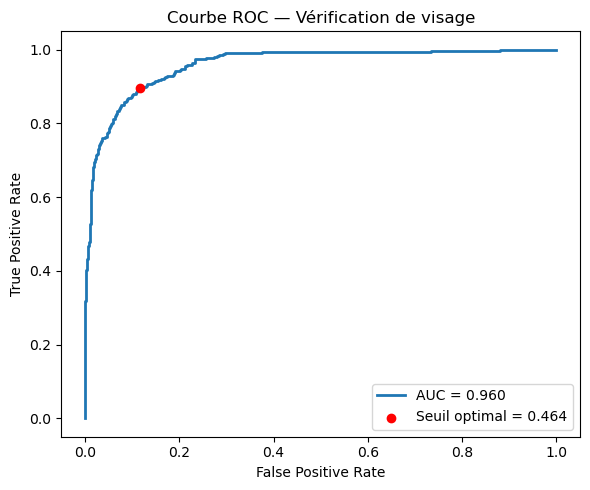

✅ roc_curve.png sauvegardé
Seuil optimal : 0.4635

  ÉVALUATION COMPLÈTE — Reconnaissance faciale
  Paires générées       :   2733
  Seuil optimal         : 0.4842
----------------------------------------------------
  AUC                   : 0.9617
  EER                   : 10.21 %
  TAR @ FAR=1 %         : 48.54 %
  TAR @ FAR=0.1 %       : 10.13 %
----------------------------------------------------
  Précision             : 86.09 %
  Rappel (TPR)          : 92.22 %
  F1-Score              : 0.8905
----------------------------------------------------
  Vrais Positifs  (TP)  : 1102
  Faux Positifs   (FP)  : 178  ← imposteurs acceptés
  Faux Négatifs   (FN)  : 93  ← mêmes personnes rejetées
  Vrais Négatifs  (TN)  : 1360


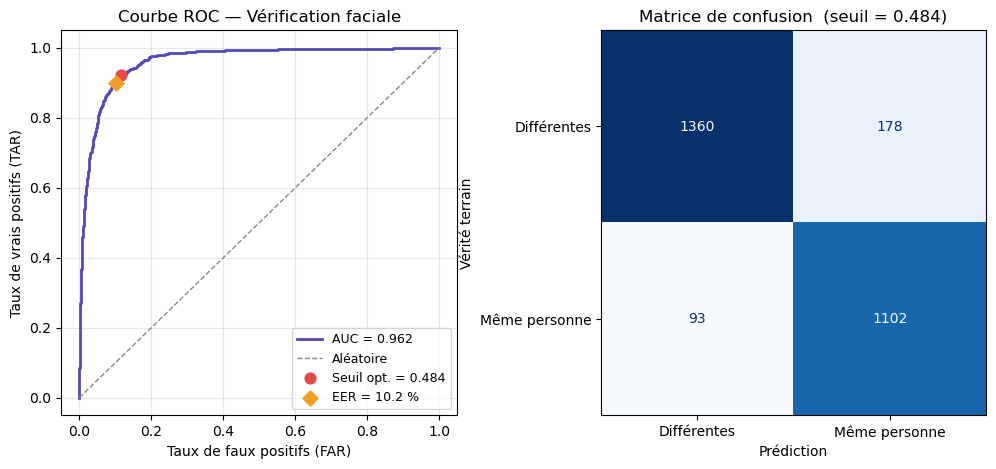

✅ evaluation_complete.png sauvegardé
Seuil optimal : 0.4842


In [2]:
# Trouver le seuil optimal automatiquement
# Ancien (garde la courbe ROC simple)
VERIFY_THRESHOLD = evaluate_verification(X_test, y_test, embedding_net)
print(f"Seuil optimal : {VERIFY_THRESHOLD:.4f}")

# Nouveau (métriques complètes + matrice de confusion)
results = evaluate_full(X_test, y_test, model=embedding_net, n_pairs=3000)
VERIFY_THRESHOLD = results["best_threshold"]  # met à jour le seuil
print(f"Seuil optimal : {VERIFY_THRESHOLD:.4f}")

## 3. Inference examples

Two photos of the same person → small distance; two different people → large distance.

In [6]:
result = verify(
    "./lfw_dataset/lfw-deepfunneled/lfw-deepfunneled/George_W_Bush/George_W_Bush_0001.jpg",
    "./lfw_dataset/lfw-deepfunneled/lfw-deepfunneled/George_W_Bush/George_W_Bush_0002.jpg",
    threshold=0.4635
)
print(result)


{'same_person': True, 'distance': 0.143, 'confidence': 84.6, 'threshold': 0.4635}


In [7]:
# construire la galerie (base des personnes connues)
df_gallery = df.groupby("person").head(2).copy()

gallery = build_gallery(df_gallery)

# test identification
result2 = identify(
    "./lfw_dataset/lfw-deepfunneled/lfw-deepfunneled/George_W_Bush/George_W_Bush_0003.jpg",
    gallery,
    threshold=0.4635
)

print(result2)

✅ Galerie : 423 personnes
{'identity': 'George_W_Bush', 'distance': 0.1428, 'confidence': 84.6, 'all_scores': [('George_W_Bush', 0.1428), ('Jean_Charest', 0.1872), ('Allyson_Felix', 0.2151), ('Frank_Solich', 0.2343), ('Richard_Myers', 0.2556)]}


In [8]:
result = verify(
    "./lfw_dataset/lfw-deepfunneled/lfw-deepfunneled/George_W_Bush/George_W_Bush_0001.jpg",
    "./lfw_dataset/lfw-deepfunneled/lfw-deepfunneled/Zydrunas_Ilgauskas/Zydrunas_Ilgauskas_0001.jpg",
    threshold=0.4635
)
print(result)

{'same_person': False, 'distance': 0.6763, 'confidence': 27.0, 'threshold': 0.4635}


In [9]:
# construire la galerie (base des personnes connues)
df_gallery = df.groupby("person").head(2).copy()

gallery = build_gallery(df_gallery)

# test identification
result2 = identify(
    "./lfw_dataset/lfw-deepfunneled/lfw-deepfunneled/Tom_Crean/Tom_Crean_0005.jpg",
    gallery,
    threshold=0.4635
)

print(result2)

✅ Galerie : 423 personnes
{'identity': 'Tom_Crean', 'distance': 0.2513, 'confidence': 72.9, 'all_scores': [('Tom_Crean', 0.2513), ('Monica_Seles', 0.2513), ('Jon_Gruden', 0.3025), ('Winona_Ryder', 0.3172), ('Steve_Nash', 0.3246)]}
